## Gradient Descent and Learning Rates

### Learning Goals
* Understand how derivatives dictate the direction of steepest descent in parameter space.
* Implement gradient descent updates for model parameters in Python.
* Analyze how different learning rates ($\eta$) affect convergence speed, oscillation, and numerical stability.

---

### 1. The Derivative Tells Us Which Way to Move

Suppose our model loss function is defined as a quadratic function of parameter $w$:
$$
L(w) = (w - 4)^2
$$
The derivative (gradient) with respect to $w$ is:
$$
\frac{dL}{dw} = 2(w - 4)
$$

Gradient descent iteratively updates the parameter in the direction opposite to the gradient:
$$
w_{t+1} = w_t - \eta \frac{dL}{dw_t}
$$
where the learning rate $\eta$ determines the step size.

<>:21: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:21: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
/tmp/ipykernel_4044/704302313.py:21: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  plt.plot(history, marker=".", linewidth=1.5, label=f"$\eta = {rate}$")


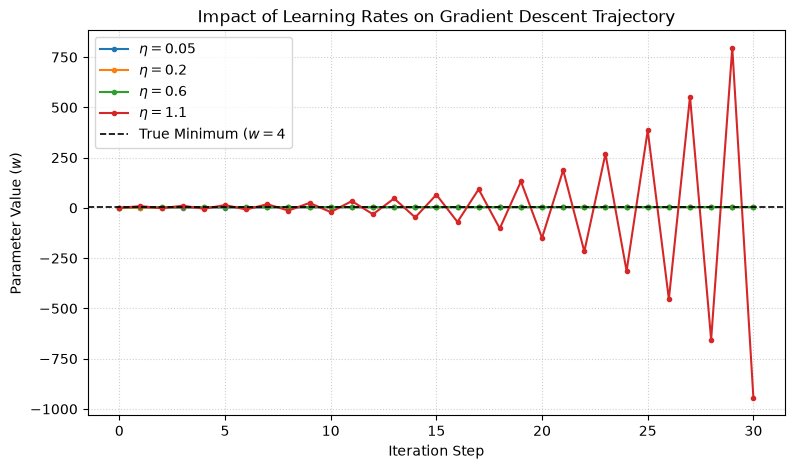

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def loss(w):
    return (w - 4)**2

def gradient(w):
    return 2 * (w - 4)

def optimize(learning_rate, initial_w=0.0, steps=30):
    w = float(initial_w)
    history = [w]
    for _ in range(steps):
        w -= learning_rate * gradient(w)
        history.append(w)
    return np.array(history)

plt.figure(figsize=(9, 5))
for rate in [0.05, 0.2, 0.6, 1.1]:
    history = optimize(rate)
    plt.plot(history, marker=".", linewidth=1.5, label=f"$\eta = {rate}$")

plt.axhline(4.0, color='black', linestyle="--", linewidth=1.2, label="True Minimum ($w=4$")
plt.xlabel("Iteration Step")
plt.ylabel("Parameter Value ($w$)")
plt.title("Impact of Learning Rates on Gradient Descent Trajectory")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 2. Interpreting the Learning Rate

* **Too Small ($\eta = 0.05$):** Progress is steady but slow, requiring many iterations to reach the minimum.
* **Suitable Rate ($\eta = 0.2, 0.6$):** Approaches the minimum efficiently without excessive oscillation.
* **Too Large ($\eta = 1.1$):** Overshoots the minimum, causing oscillation or complete numerical divergence.

> **Real-World Complexity:** While this example illustrates a simple 1D convex function, deep neural networks feature millions of parameters and highly non-convex loss surfaces.

---

### Exercises

Try each problem before running the answer-checking code below:

1. Test an extremely small learning rate ($\eta = 0.001$) and observe how many steps are needed to reach $w = 4$.
2. Test an oversized learning rate ($\eta = 1.2$) and observe what happens to the trajectory.
3. Explain why the gradient descent update rule **subtracts** the gradient term ($\eta \frac{dL}{dw}$).
4. What happens in practice if gradients become extremely large during training (exploding gradients)?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1 & 2 tests
hist_small = optimize(0.001, steps=50)
hist_large = optimize(1.2, steps=10)

print(f"\n1. Tiny Learning Rate (eta = 0.001):")
print(f"   - Final w after 50 steps: {hist_small[-1]:.4f} (slow convergence, far from 4.0)")

print(f"\n2. Oversized Learning Rate (eta = 1.2):")
print(f"   - Final w after 10 steps: {hist_large[-1]:.4f} (diverges / oscillates wildly)")

print("\n3. Why We Subtract the Gradient:")
print("   - The gradient points in the direction of steepest *increase* in loss;")
print("     subtracting it moves the parameter in the direction of steepest *decrease* toward the minimum.")

print("\n4. Exploding Gradients:")
print("   - Extremely large gradients cause massive parameter updates that push the loss to infinity")
print("     (resulting in NaN values), which is mitigated via techniques like gradient clipping.")

=== Exercise Solutions & Checks ===

1. Tiny Learning Rate (eta = 0.001):
   - Final w after 50 steps: 0.3810 (slow convergence, far from 4.0)

2. Oversized Learning Rate (eta = 1.2):
   - Final w after 10 steps: -111.7019 (diverges / oscillates wildly)

3. Why We Subtract the Gradient:
   - The gradient points in the direction of steepest *increase* in loss;
     subtracting it moves the parameter in the direction of steepest *decrease* toward the minimum.

4. Exploding Gradients:
   - Extremely large gradients cause massive parameter updates that push the loss to infinity
     (resulting in NaN values), which is mitigated via techniques like gradient clipping.
